# LLM SFT & Preference Alignment Analysis
### *Model Accuracies, Visualizations, and Leaderboard Tables Across 3 Annotation Tasks*

This notebook provides a **unified dashboard** that combines our visual plotting engine and leaderboard table generators. It parses the baseline Excel dataset and our alignment experimental outputs, plotting performance curves and producing publication-quality tables.

#### Table of Contents
1. [Setup and Settings](#1.-Setup-and-Settings)
2. [Main Paper Figure (Accuracy vs. Training Size)](#2.-Main-Paper-Figure-(Accuracy-vs.-Training-Size))
3. [Table 7: Configuration Leaderboard](#3.-Table-7:-Configuration-Leaderboard)
4. [Table 8: Model Performance Comparison (Gemma 3 vs. Llama 3.1)](#4.-Table-8:-Model-Performance-Comparison-(Gemma-3-vs.-Llama-3.1))
5. [Detailed Configuration Analysis (Task-by-Task, F1 & Accuracy)](#5.-Detailed-Configuration-Analysis-(Task-by-Task,-F1-&-Accuracy))
6. [Seed-level Confusion Matrices & ROC Curves](#6.-Seed-level-Confusion-Matrices-&-ROC-Curves)

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
import matplotlib.lines as mlines
from IPython.display import display, Markdown, HTML

# Configure high-quality Seaborn styling for academic figures
sns.set_theme(style="white")
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'Helvetica', 'DejaVu Sans'],
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 13,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 9.5,
    'figure.titlesize': 14,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight'
})
%matplotlib inline

print("Libraries successfully imported and visual properties set!")

Libraries successfully imported and visual properties set!


## 1. Main Paper Figure (Accuracy vs. Training Size)

In this section, we parse baseline configurations (ChatGPT 3.5 and Llama 3 8B) from our Excel data, alongside the primary SFT & alignment experimental runs (DPO Hard Neg, DPO Rand Wrong, and KTO All Wrong) for Llama 3.1 and Gemma 3. We also plot the Llama 3.1 8B Zero-Shot baseline as a horizontal benchmark line.

In [2]:
def load_alignment_baseline(script_dir, model_id, task_id, config_name):
    """Loads the unique baseline accuracy_mean * 100 for zero-shot line."""
    file_path = os.path.join(script_dir, 'beyond_sft_alignment_light', model_id, task_id, 'unified_colab', 'single_adapter_multi_inference', task_id, 'tables', 'aggregated_summary.csv')
    
    if not os.path.exists(file_path):
        file_path = os.path.join(script_dir, 'beyond_sft_alignment_light', model_id, task_id, 'unified_colab', 'independent_adapters', task_id, 'tables', 'aggregated_summary.csv')
        
    if not os.path.exists(file_path):
        return None
        
    try:
        df = pd.read_csv(file_path)
        sub = df[df['method'] == config_name]
        if sub.empty:
            return None
        return sub['accuracy_mean'].values[0] * 100
    except Exception as e:
        print(f"Error loading baseline {model_id} {task_id} {config_name}: {e}")
        return None

def load_alignment_data(script_dir, model_id, task_id, config_name):
    """Loads train_size and accuracy_mean from alignment aggregated summaries."""
    file_path = os.path.join(script_dir, 'beyond_sft_alignment_light', model_id, task_id, 'unified_colab', 'single_adapter_multi_inference', task_id, 'tables', 'aggregated_summary.csv')
    
    if not os.path.exists(file_path):
        file_path = os.path.join(script_dir, 'beyond_sft_alignment_light', model_id, task_id, 'unified_colab', 'independent_adapters', task_id, 'tables', 'aggregated_summary.csv')
        
    if not os.path.exists(file_path):
        return None
        
    try:
        df = pd.read_csv(file_path)
        df['full_config'] = (df['method'] + '_' + df['preference_strategy'] + '_' + df['data_allocation']).str.replace('_na', '')
        
        sub = df[df['full_config'] == config_name]
        if sub.empty:
            return None
            
        sub = sub.copy()
        sub['train_size'] = sub['train_size'].astype(int)
        sub['accuracy_pct'] = sub['accuracy_mean'] * 100
        sub = sub.sort_values(by='train_size')
        
        return sub[['train_size', 'accuracy_pct']].values
    except Exception as e:
        print(f"Error loading {model_id} {task_id} {config_name}: {e}")
        return None

In [3]:
def plot_accuracy_figures(workspace_dir):
    excel_path = os.path.join(workspace_dir, 'Result value accuracy Alizadeh.xlsx')
    
    if not os.path.exists(excel_path):
        print(f"Error: Excel file not found at {excel_path}")
        return
        
    df_excel = pd.read_excel(excel_path, sheet_name='Feuil1')
    df_excel = df_excel.dropna(subset=['Dataset', 'Task', 'Group'])
    
    tasks = [
        {
            'dataset': 'Tweets (2020-2021)',
            'task': 'Policy Frames (Super Frames)',
            'internal_id': 'ds1_task6',
            'title': 'Tweets (2020–2021)\nPolicy Frames'
        },
        {
            'dataset': 'News Articles (2020-2021)',
            'task': 'Problem/Solution',
            'internal_id': 'ds4_task2',
            'title': 'News Articles (2020–2021)\nProblem/Solution'
        },
        {
            'dataset': 'Tweets (2017-2022)',
            'task': 'Policy Frames (Super Frames)',
            'internal_id': 'ds3_task6',
            'title': 'Tweets (2017–2022)\nPolicy Frames'
        }
    ]
    
    # Unified list-driven configuration representing all curves
    curves_to_plot = [
        # --- 1. Excel Baselines ---
        {
            'type': 'excel',
            'group': 'ChatGPT',
            'shot': 'Fine-Tuning',
            'label': 'ChatGPT 3.5 (Fine-Tuning)',
            'style': {'color': '#10A37F', 'linestyle': '-', 'marker': 's', 'markersize': 5, 'linewidth': 1.5}
        },
        {
            'type': 'excel_horizontal',
            'group': 'ChatGPT',
            'shot': 'Zero-Shot',
            'label': 'ChatGPT 3.5 (Zero-Shot)',
            'style': {'color': '#10A37F', 'linestyle': '--', 'linewidth': 1.2, 'alpha': 0.7}
        },
        {
            'type': 'excel',
            'group': 'Llama 3 8b',
            'shot': 'Fine-Tuning',
            'label': 'Llama 3 8B (Fine-Tuning)',
            'style': {'color': '#64748B', 'linestyle': '-', 'marker': 'o', 'markersize': 5, 'linewidth': 1.5}
        },
        {
            'type': 'excel_horizontal',
            'group': 'Llama 3 8b',
            'shot': 'Zero-Shot',
            'label': 'Llama 3 8B (Zero-Shot)',
            'style': {'color': '#64748B', 'linestyle': '--', 'linewidth': 1.2, 'alpha': 0.7}
        },
        
        # --- 2. Llama 3.1 Curves ---
        {
            'type': 'alignment_horizontal',
            'model_id': 'llama31',
            'config_name': 'pretrained_baseline',
            'label': 'Llama 3.1 8B (Zero-Shot)',
            'style': {'color': '#2563EB', 'linestyle': '-.', 'linewidth': 1.4, 'alpha': 0.8}
        },
        {
            'type': 'alignment',
            'model_id': 'llama31',
            'config_name': 'sft_dpo_hard_negative_shared',
            'label': 'Llama 3.1 (DPO Hard Neg)',
            'style': {'color': '#1E3A8A', 'linestyle': '-', 'marker': '^', 'markersize': 6, 'linewidth': 2.0}
        },
        {
            'type': 'alignment',
            'model_id': 'llama31',
            'config_name': 'sft_dpo_random_wrong_shared',
            'label': 'Llama 3.1 (DPO Rand Wrong)',
            'style': {'color': '#3B82F6', 'linestyle': '--', 'marker': 'v', 'markersize': 6, 'linewidth': 1.8}
        },
        {
            'type': 'alignment',
            'model_id': 'llama31',
            'config_name': 'sft_kto_all_wrong_shared',
            'label': 'Llama 3.1 (KTO All Wrong)',
            'style': {'color': '#06B6D4', 'linestyle': ':', 'marker': '<', 'markersize': 6, 'linewidth': 1.8}
        },
        
        # --- 3. Gemma 3 Curves ---
        {
            'type': 'alignment',
            'model_id': 'gemma3',
            'config_name': 'sft_dpo_hard_negative_shared',
            'label': 'Gemma 3 (DPO Hard Neg)',
            'style': {'color': '#5B21B6', 'linestyle': '-', 'marker': 'D', 'markersize': 5.5, 'linewidth': 2.0}
        },
        {
            'type': 'alignment',
            'model_id': 'gemma3',
            'config_name': 'sft_dpo_random_wrong_shared',
            'label': 'Gemma 3 (DPO Rand Wrong)',
            'style': {'color': '#8B5CF6', 'linestyle': '--', 'marker': 'd', 'markersize': 5.5, 'linewidth': 1.8}
        },
        {
            'type': 'alignment',
            'model_id': 'gemma3',
            'config_name': 'sft_kto_all_wrong_shared',
            'label': 'Gemma 3 (KTO All Wrong)',
            'style': {'color': '#EC4899', 'linestyle': ':', 'marker': '*', 'markersize': 7.5, 'linewidth': 1.8}
        }
    ]
    
    fig, axes = plt.subplots(1, 3, figsize=(15, 6.2), sharey=False)
    
    for idx, t_info in enumerate(tasks):
        ax = axes[idx]
        task_df = df_excel[(df_excel['Dataset'] == t_info['dataset']) & (df_excel['Task'] == t_info['task'])]
        
        # Plot each curve sequentially
        for curve in curves_to_plot:
            ctype = curve['type']
            style = curve['style']
            
            if ctype == 'excel':
                sub_df = task_df[(task_df['Group'] == curve['group']) & (task_df['Shot'] == curve['shot'])].sort_values(by='Rows')
                if not sub_df.empty:
                    ax.plot(sub_df['Rows'].values, sub_df['Accuracy'].values, **style)
                    
            elif ctype == 'excel_horizontal':
                sub_df = task_df[(task_df['Group'] == curve['group']) & (task_df['Shot'] == curve['shot'])]
                if not sub_df.empty:
                    ax.axhline(y=sub_df['Accuracy'].values[0], **style)
                    
            elif ctype == 'alignment_horizontal':
                val = load_alignment_baseline(workspace_dir, curve['model_id'], t_info['internal_id'], curve['config_name'])
                if val is not None:
                    ax.axhline(y=val, **style)
                    
            elif ctype == 'alignment':
                data = load_alignment_data(workspace_dir, curve['model_id'], t_info['internal_id'], curve['config_name'])
                if data is not None and len(data) > 0:
                    ax.plot(data[:, 0], data[:, 1], **style)
                    
        # Formatting subplot details
        ax.set_title(t_info['title'].replace('\\n', '\n'), fontsize=12.5, fontweight='bold', pad=15)
        ax.set_xlabel('Training Dataset Size (number of rows)', fontsize=10, labelpad=8)
        
        if idx == 0:
            ax.set_ylabel('Accuracy (%)', fontsize=11, fontweight='bold', labelpad=8)
        else:
            ax.set_ylabel('Accuracy (%)', fontsize=10, labelpad=8)
            
        ax.set_xscale('log')
        
        # Dynamically set ticks
        all_sizes = list(task_df[task_df['Shot'] == 'Fine-Tuning']['Rows'].unique())
        for curve in curves_to_plot:
            if curve['type'] == 'alignment':
                data = load_alignment_data(workspace_dir, curve['model_id'], t_info['internal_id'], curve['config_name'])
                if data is not None:
                    all_sizes.extend(list(data[:, 0]))
        unique_sizes = sorted(list(set(all_sizes)))
        
        ax.set_xticks(unique_sizes)
        ax.get_xaxis().set_major_formatter(ticker.ScalarFormatter())
        ax.set_xlim(min(unique_sizes) * 0.8, max(unique_sizes) * 1.25)
        ax.yaxis.set_major_formatter(ticker.PercentFormatter(decimals=0))
        ax.grid(True, which='both', linestyle=':', alpha=0.5, color='#CBD5E1')
        sns.despine(ax=ax, top=True, right=True)
        ax.set_ylim(20, 95)

    # Draw Legend
    legend_handles = []
    legend_labels = []
    for curve in curves_to_plot:
        style = curve['style']
        label = curve['label']
        
        if 'marker' in style:
            handle = mlines.Line2D([], [], 
                                   color=style['color'], 
                                   linestyle=style['linestyle'],
                                   marker=style['marker'], 
                                   markersize=style['markersize'], 
                                   linewidth=style['linewidth'],
                                   label=label)
        else:
            handle = mlines.Line2D([], [], 
                                   color=style['color'], 
                                   linestyle=style['linestyle'],
                                   linewidth=style['linewidth'],
                                   alpha=style.get('alpha', 1.0),
                                   label=label)
        legend_handles.append(handle)
        legend_labels.append(label)
        
    fig.legend(handles=legend_handles, labels=legend_labels,
               loc='lower center', 
               bbox_to_anchor=(0.5, -0.18), 
               ncol=4, 
               frameon=True, 
               facecolor='white', 
               edgecolor='#E2E8F0',
               fontsize=10)
    
    plt.tight_layout()
    plt.subplots_adjust(bottom=0.24)
    plt.show()

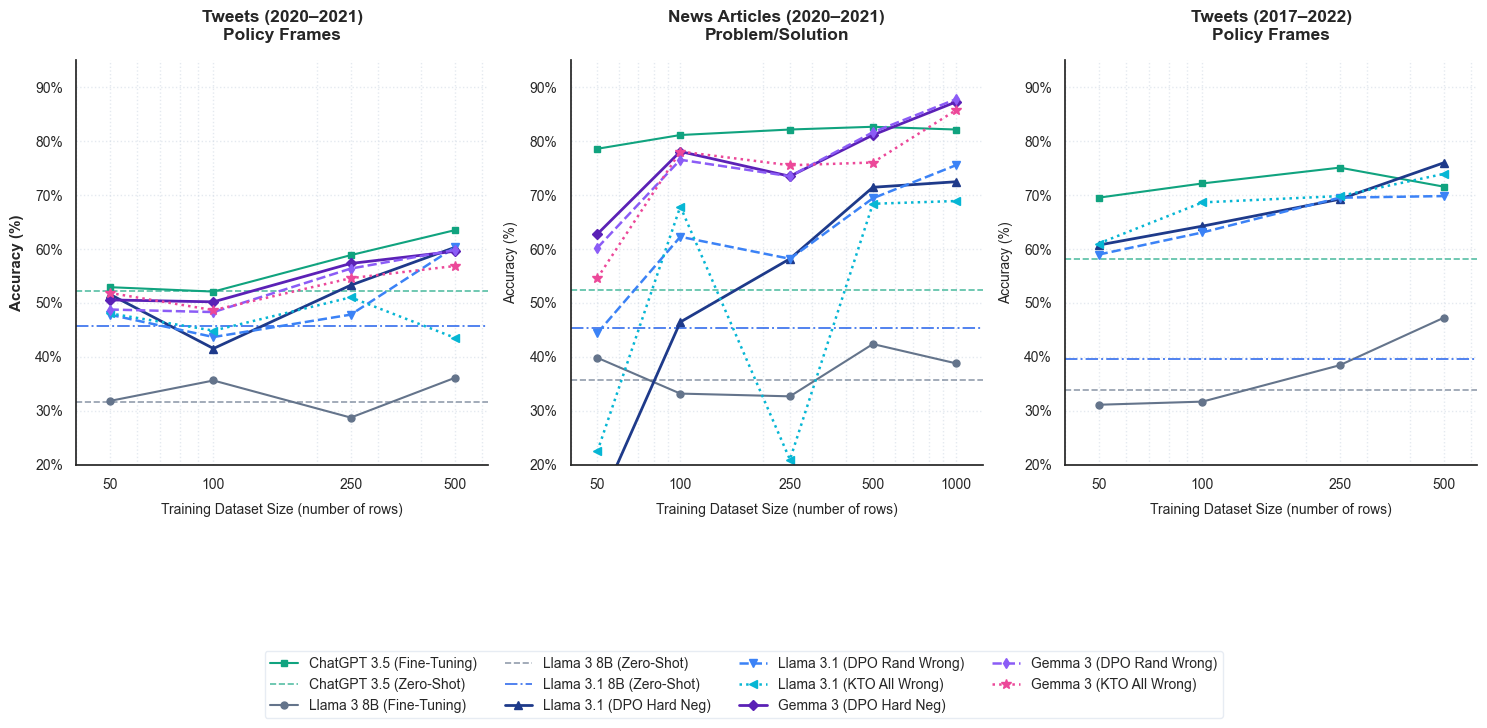

In [4]:
# Generate the plot inline
plot_accuracy_figures(os.getcwd())

## 2. Table 7: Configuration Leaderboard

This table identifies the **best alignment configuration** for each task and training size based on macro F1-score, and calculates the margin against the second-best configuration and standard SFT configuration.

In [5]:
def get_table7_data(script_dir):
    task_mapping = {'Task 1': 'ds1_task6', 'Task 2': 'ds4_task2', 'Task 3': 'ds3_task6'}
    models_map = {'Llama3.1': 'llama31', 'Gemma3': 'gemma3'}
    train_sizes = [50, 100, 250, 500, 1000]
    
    table_data = {}
    for task_friendly, task_internal in task_mapping.items():
        table_data[task_friendly] = {}
        for model_friendly, model_internal in models_map.items():
            table_data[task_friendly][model_friendly] = {}
            file_path = os.path.join(script_dir, 'beyond_sft_alignment_light', model_internal, task_internal, 'unified_colab', 'single_adapter_multi_inference', task_internal, 'tables', 'aggregated_summary.csv')
            if not os.path.exists(file_path):
                file_path = os.path.join(script_dir, 'beyond_sft_alignment_light', model_internal, task_internal, 'unified_colab', 'independent_adapters', task_internal, 'tables', 'aggregated_summary.csv')
            
            if not os.path.exists(file_path):
                for t_size in train_sizes:
                    table_data[task_friendly][model_friendly][t_size] = None
            else:
                df = pd.read_csv(file_path)
                for t_size in train_sizes:
                    df_size = df[df['train_size'].astype(str) == str(t_size)]
                    if df_size.empty:
                        table_data[task_friendly][model_friendly][t_size] = None
                        continue
                    sft_df = df_size[df_size['method'] == 'sft']
                    sft_max_f1 = sft_df['macro_f1_mean'].max() if not sft_df.empty else np.nan
                    
                    df_size = df_size[df_size['method'] != 'pretrained_baseline']
                    df_size = df_size.sort_values(by='macro_f1_mean', ascending=False)
                    if len(df_size) == 0:
                        table_data[task_friendly][model_friendly][t_size] = None
                        continue
                    
                    best_row = df_size.iloc[0]
                    best_f1 = best_row['macro_f1_mean']
                    best_config_name = f"{best_row['method']}_{best_row['preference_strategy']}_{best_row['data_allocation']}".replace('_na', '')
                    
                    second_best_f1 = np.nan
                    if len(df_size) > 1:
                        second_best_f1 = df_size.iloc[1]['macro_f1_mean']
                    
                    gap_2nd = (best_f1 - second_best_f1) * 100 if not pd.isna(second_best_f1) else np.nan
                    gap_sft = (best_f1 - sft_max_f1) * 100 if not pd.isna(sft_max_f1) else np.nan
                    
                    table_data[task_friendly][model_friendly][t_size] = {
                        'config': best_config_name, 'gap_2nd': gap_2nd, 'gap_sft': gap_sft
                    }
    return table_data, train_sizes

def display_table7(table_data, train_sizes):
    rows = []
    for task in ['Task 1', 'Task 2', 'Task 3']:
        for model in ['Llama3.1', 'Gemma3']:
            row_dict = {'Task': task, 'Model': model}
            for t_size in train_sizes:
                info = table_data[task][model][t_size]
                if info is None:
                    row_dict[str(t_size)] = "NA"
                else:
                    g2_str = f"+{info['gap_2nd']:.1f}%" if info['gap_2nd'] >= 0 else f"{info['gap_2nd']:.1f}%"
                    gs_str = f"+{info['gap_sft']:.1f}%" if info['gap_sft'] >= 0 else f"{info['gap_sft']:.1f}%"
                    row_dict[str(t_size)] = f"<b>{info['config']}</b><br><span style='font-size: 10px; color:#475569;'>({g2_str} 2nd, {gs_str} SFT)</span>"
            rows.append(row_dict)
            
    df_t7 = pd.DataFrame(rows)
    
    # Output HTML display for visual excellence
    html = df_t7.to_html(escape=False, index=False)
    # Custom table style injection
    styled_html = f"""
    <style>
        .styled-table {{ border-collapse: collapse; width: 100%; font-family: sans-serif; font-size: 11px; margin-top: 10px; }}
        .styled-table th, .styled-table td {{ border: 1px solid #CBD5E1; padding: 8px; text-align: center; vertical-align: middle; }}
        .styled-table th {{ background-color: #F1F5F9; font-weight: bold; }}
        .styled-table td b {{ font-family: monospace; font-size: 11px; color: #1E293B; background: #F8FAFC; padding: 2px 4px; border-radius: 4px; }}
    </style>
    """ + html.replace('class="dataframe"', 'class="styled-table"')
    display(HTML(styled_html))

In [6]:
t7_data, train_sizes = get_table7_data(os.getcwd())
display_table7(t7_data, train_sizes)

Task,Model,50,100,250,500,1000
Task 1,Llama3.1,"sft_kto_all_wrong_sft25_dpo75(+0.6% 2nd, +1.2% SFT)","sft_dpo_random_wrong_sft25_dpo75(+2.3% 2nd, +2.3% SFT)","sft_dpo_hard_negative_sft25_dpo75(+0.2% 2nd, +1.0% SFT)","sft_dpo_random_wrong_shared(+0.3% 2nd, +3.0% SFT)",NA
Task 1,Gemma3,"kto_all_wrong_shared(+0.9% 2nd, +5.2% SFT)","kto_all_wrong_shared(+0.4% 2nd, +8.5% SFT)","sft_dpo_hard_negative_shared(+0.6% 2nd, +0.6% SFT)","sft_shared(+0.2% 2nd, +0.0% SFT)",NA
Task 2,Llama3.1,"sft_dpo_random_wrong_sft25_dpo75(+0.9% 2nd, +1.2% SFT)","sft_kto_all_wrong_shared(+1.7% 2nd, +1.7% SFT)","sft_shared(+4.0% 2nd, +0.0% SFT)","sft_dpo_random_wrong_shared(+0.2% 2nd, +5.4% SFT)","sft_dpo_random_wrong_shared(+0.9% 2nd, +3.8% SFT)"
Task 2,Gemma3,"sft_dpo_hard_negative_shared(+0.4% 2nd, +0.4% SFT)","sft_dpo_random_wrong_shared(+1.0% 2nd, +1.0% SFT)","sft_kto_all_wrong_shared(+0.4% 2nd, +2.1% SFT)","kto_all_wrong_shared(+0.8% 2nd, +1.8% SFT)","sft_dpo_random_wrong_shared(+0.7% 2nd, +1.0% SFT)"
Task 3,Llama3.1,"sft_dpo_hard_negative_shared(+0.9% 2nd, +4.9% SFT)","sft_dpo_hard_negative_shared(+1.1% 2nd, +2.0% SFT)","sft_shared(+3.0% 2nd, +0.0% SFT)","sft_shared(+0.2% 2nd, +0.0% SFT)",NA
Task 3,Gemma3,NA,NA,NA,NA,NA


## 3. Table 8: Model Performance Comparison (Gemma 3 vs. Llama 3.1)

This table directly compares the best configuration's performance (macro F1-score / Accuracy in %) between Gemma 3 and Llama 3.1 across training sizes, featuring a **Diff (Gemma - Llama)** row.

In [7]:
def get_table8_data(script_dir):
    task_mapping = {'Task 1': 'ds1_task6', 'Task 2': 'ds4_task2', 'Task 3': 'ds3_task6'}
    models_map = {'Llama3.1': 'llama31', 'Gemma3': 'gemma3'}
    train_sizes = [50, 100, 250, 500, 1000]
    
    results_data = {}
    for task_friendly, task_internal in task_mapping.items():
        results_data[task_friendly] = {}
        for model_friendly, model_internal in models_map.items():
            results_data[task_friendly][model_friendly] = {}
            file_path = os.path.join(script_dir, 'beyond_sft_alignment_light', model_internal, task_internal, 'unified_colab', 'single_adapter_multi_inference', task_internal, 'tables', 'aggregated_summary.csv')
            if not os.path.exists(file_path):
                file_path = os.path.join(script_dir, 'beyond_sft_alignment_light', model_internal, task_internal, 'unified_colab', 'independent_adapters', task_internal, 'tables', 'aggregated_summary.csv')
            
            if not os.path.exists(file_path):
                for t_size in train_sizes:
                    results_data[task_friendly][model_friendly][t_size] = None
            else:
                df = pd.read_csv(file_path)
                for t_size in train_sizes:
                    df_size = df[df['train_size'].astype(str) == str(t_size)]
                    if df_size.empty:
                        results_data[task_friendly][model_friendly][t_size] = None
                        continue
                    df_size = df_size[df_size['method'] != 'pretrained_baseline']
                    df_size = df_size.sort_values(by='macro_f1_mean', ascending=False)
                    if len(df_size) == 0:
                        results_data[task_friendly][model_friendly][t_size] = None
                        continue
                    best_row = df_size.iloc[0]
                    results_data[task_friendly][model_friendly][t_size] = {
                        'f1': best_row['macro_f1_mean'] * 100, 'acc': best_row['accuracy_mean'] * 100
                    }
    return results_data, train_sizes

def display_table8(results_data, train_sizes):
    rows = []
    for task in ['Task 1', 'Task 2', 'Task 3']:
        # Llama3.1 row
        l_dict = {'Task': task, 'Model': 'Llama3.1'}
        for t in train_sizes:
            info = results_data[task]['Llama3.1'][t]
            l_dict[str(t)] = f"{info['f1']:.1f}% / {info['acc']:.1f}%" if info else "NA"
        rows.append(l_dict)
        
        # Gemma3 row
        g_dict = {'Task': task, 'Model': 'Gemma3'}
        for t in train_sizes:
            info = results_data[task]['Gemma3'][t]
            g_dict[str(t)] = f"{info['f1']:.1f}% / {info['acc']:.1f}%" if info else "NA"
        rows.append(g_dict)
        
        # Diff row
        d_dict = {'Task': task, 'Model': 'Diff (Gemma - Llama)'}
        for t in train_sizes:
            llama_info = results_data[task]['Llama3.1'][t]
            gemma_info = results_data[task]['Gemma3'][t]
            if llama_info is None or gemma_info is None:
                d_dict[str(t)] = "NA"
            else:
                d_f1 = gemma_info['f1'] - llama_info['f1']
                d_acc = gemma_info['acc'] - llama_info['acc']
                f1_str = f"+{d_f1:.1f}%" if d_f1 >= 0 else f"{d_f1:.1f}%"
                acc_str = f"+{d_acc:.1f}%" if d_acc >= 0 else f"{d_acc:.1f}%"
                d_dict[str(t)] = f"<b>{f1_str} / {acc_str}</b>"
        rows.append(d_dict)
        
    df_t8 = pd.DataFrame(rows)
    
    # Output HTML
    html = df_t8.to_html(escape=False, index=False)
    styled_html = """
    <style>
        .styled-table2 { border-collapse: collapse; width: 100%; font-family: sans-serif; font-size: 11px; margin-top: 10px; }
        .styled-table2 th, .styled-table2 td { border: 1px solid #CBD5E1; padding: 8px; text-align: center; vertical-align: middle; }
        .styled-table2 th { background-color: #F1F5F9; font-weight: bold; }
        .styled-table2 tr.diff-row { background: #F8FAFC; font-weight: bold; font-style: italic; }
        .styled-table2 tr.diff-row td b { color: #2563EB; }
    </style>
    """ + html.replace('class="dataframe"', 'class="styled-table2"')
    
    display(HTML(styled_html))


In [8]:
t8_data, train_sizes = get_table8_data(os.getcwd())
display_table8(t8_data, train_sizes)

Task,Model,50,100,250,500,1000
Task 1,Llama3.1,51.5% / 53.6%,51.0% / 53.0%,52.1% / 54.6%,58.3% / 60.3%,NA
Task 1,Gemma3,54.5% / 57.2%,54.3% / 57.5%,54.3% / 57.3%,58.0% / 60.5%,NA
Task 1,Diff (Gemma - Llama),+3.1% / +3.6%,+3.3% / +4.5%,+2.3% / +2.7%,-0.3% / +0.3%,NA
Task 2,Llama3.1,46.2% / 58.2%,47.0% / 67.9%,53.4% / 64.8%,60.1% / 69.4%,66.1% / 75.5%
Task 2,Gemma3,55.0% / 62.8%,61.3% / 76.5%,66.1% / 75.5%,74.0% / 81.6%,81.3% / 87.8%
Task 2,Diff (Gemma - Llama),+8.9% / +4.6%,+14.3% / +8.7%,+12.7% / +10.7%,+13.9% / +12.2%,+15.2% / +12.2%
Task 3,Llama3.1,59.3% / 60.7%,59.6% / 64.2%,63.7% / 70.1%,70.4% / 73.9%,NA
Task 3,Gemma3,NA,NA,NA,NA,NA
Task 3,Diff (Gemma - Llama),NA,NA,NA,NA,NA


## 4. Detailed Configuration Analysis (Task-by-Task, F1 & Accuracy)

In this section, we show a comprehensive side-by-side performance analysis of **every single experimental configuration** (SFT, DPO, KTO, standard baselines, and various preferences/allocations) for both models. 

For each task:
- **Left Plot**: Macro F1-Score (%) vs. Training Size
- **Right Plot**: Accuracy (%) vs. Training Size

Llama 3.1 configurations are colored using a cool teal-blue gradient (`crest`), and Gemma 3 configurations are colored using a warm magenta-orange gradient (`flare`) to keep model families visually distinct.

In [9]:
def load_all_task_configs(script_dir, model_id, task_id):
    """Loads all configurations and their macro_f1 / accuracy metrics from tables."""
    file_path = os.path.join(script_dir, 'beyond_sft_alignment_light', model_id, task_id, 'unified_colab', 'single_adapter_multi_inference', task_id, 'tables', 'aggregated_summary.csv')
    if not os.path.exists(file_path):
        file_path = os.path.join(script_dir, 'beyond_sft_alignment_light', model_id, task_id, 'unified_colab', 'independent_adapters', task_id, 'tables', 'aggregated_summary.csv')
    if not os.path.exists(file_path):
        return {}
        
    try:
        df = pd.read_csv(file_path)
        df['full_config'] = (df['method'] + '_' + df['preference_strategy'] + '_' + df['data_allocation']).str.replace('_na', '')
        
        configs = {}
        for conf_name in df['full_config'].unique():
            sub = df[df['full_config'] == conf_name].copy()
            sub = sub.dropna(subset=['train_size'])
            sub['train_size'] = sub['train_size'].astype(int)
            sub = sub.sort_values(by='train_size')
            
            configs[conf_name] = {
                'train_sizes': sub['train_size'].values,
                'macro_f1': sub['macro_f1_mean'].values * 100,
                'accuracy': sub['accuracy_mean'].values * 100
            }
        return configs
    except Exception as e:
        print(f"Error loading all configs for {model_id} {task_id}: {e}")
        return {}

def plot_detailed_task_configs(workspace_dir, task_friendly, task_internal):
    llama_configs = load_all_task_configs(workspace_dir, 'llama31', task_internal)
    gemma_configs = load_all_task_configs(workspace_dir, 'gemma3', task_internal)
    
    if not llama_configs and not gemma_configs:
        print(f"No configuration data found for {task_friendly}")
        return
        
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7.5))
    
    # High-contrast line style and marker list
    linestyles = ['-', '--', '-.', ':']
    markers = ['o', 's', '^', 'v', 'D', 'd', 'p', '*', 'h', 'P', 'X']
    
    # 1. Plot Llama 3.1 configs (Cool colors - Blues/Teals)
    llama_keys = sorted(llama_configs.keys())
    llama_palette = sns.color_palette("crest", n_colors=max(len(llama_keys), 1))
    
    for i, config_name in enumerate(llama_keys):
        data = llama_configs[config_name]
        color = llama_palette[i]
        linestyle = linestyles[i % len(linestyles)]
        marker = markers[i % len(markers)]
        
        lbl = f"Llama3.1: {config_name}"
        ax1.plot(data['train_sizes'], data['macro_f1'], label=lbl, color=color, 
                 linestyle=linestyle, marker=marker, markersize=5.5, linewidth=1.5)
        ax2.plot(data['train_sizes'], data['accuracy'], label=lbl, color=color, 
                 linestyle=linestyle, marker=marker, markersize=5.5, linewidth=1.5)
                 
    # 2. Plot Gemma 3 configs (Warm colors - Purples/flare gradient)
    gemma_keys = sorted(gemma_configs.keys())
    gemma_palette = sns.color_palette("flare", n_colors=max(len(gemma_keys), 1))
    
    for i, config_name in enumerate(gemma_keys):
        data = gemma_configs[config_name]
        color = gemma_palette[i]
        linestyle = linestyles[i % len(linestyles)]
        marker = markers[(i + 4) % len(markers)]
        
        lbl = f"Gemma3: {config_name}"
        ax1.plot(data['train_sizes'], data['macro_f1'], label=lbl, color=color, 
                 linestyle=linestyle, marker=marker, markersize=5.5, linewidth=1.5)
        ax2.plot(data['train_sizes'], data['accuracy'], label=lbl, color=color, 
                 linestyle=linestyle, marker=marker, markersize=5.5, linewidth=1.5)
                 
    # Formatting subplots
    for ax, metric_name in [(ax1, "Macro F1-Score (%)"), (ax2, "Accuracy (%)")]:
        ax.set_title(f"{task_friendly} - {metric_name} by Train Size", fontsize=13, fontweight='bold', pad=12)
        ax.set_xlabel("Training Dataset Size", fontsize=10, labelpad=8)
        ax.set_ylabel(metric_name, fontsize=10, labelpad=8)
        ax.set_xscale('log')
        
        # Collect unique x values dynamically
        all_x = []
        for d in list(llama_configs.values()) + list(gemma_configs.values()):
            all_x.extend(list(d['train_sizes']))
        unique_x = sorted(list(set(all_x)))
        
        ax.set_xticks(unique_x)
        ax.get_xaxis().set_major_formatter(ticker.ScalarFormatter())
        ax.set_xlim(min(unique_x) * 0.8, max(unique_x) * 1.25)
        ax.grid(True, which='both', linestyle=':', alpha=0.5, color='#CBD5E1')
        sns.despine(ax=ax, top=True, right=True)
        
    # Draw Legend on the right side
    handles, labels = ax1.get_legend_handles_labels()
    fig.legend(handles, labels, loc='center left', bbox_to_anchor=(1.01, 0.5), 
               ncol=2, frameon=True, facecolor='white', edgecolor='#E2E8F0', fontsize=8.5)
               
    plt.tight_layout()
    plt.show()

### Task 1: Tweets (2020-2021) - Policy Frames

In [10]:
plot_detailed_task_configs(os.getcwd(), 'Task 1 (Tweets 2020-2021)', 'ds1_task6')

Error loading all configs for llama31 ds1_task6: invalid literal for int() with base 10: 'na'
Error loading all configs for gemma3 ds1_task6: invalid literal for int() with base 10: 'na'
No configuration data found for Task 1 (Tweets 2020-2021)


### Task 2: News Articles (2020-2021) - Problem/Solution

In [11]:
plot_detailed_task_configs(os.getcwd(), 'Task 2 (News Articles 2020-2021)', 'ds4_task2')

Error loading all configs for llama31 ds4_task2: invalid literal for int() with base 10: 'na'
Error loading all configs for gemma3 ds4_task2: invalid literal for int() with base 10: 'na'
No configuration data found for Task 2 (News Articles 2020-2021)


### Task 3: Tweets (2017-2022) - Policy Frames

In [12]:
plot_detailed_task_configs(os.getcwd(), 'Task 3 (Tweets 2017-2022)', 'ds3_task6')

Error loading all configs for llama31 ds3_task6: invalid literal for int() with base 10: 'na'
No configuration data found for Task 3 (Tweets 2017-2022)


## 5. Seed-level Confusion Matrices & Multi-Class ROC Curves

This section presents the seed-level confusion matrices alongside the corresponding class-specific ROC curves for the alignment runs.

- **Left Plots**: Pre-generated Confusion Matrices for each seed.
- **Right Plots**: ROC Curves plotted for each class label. Since exact sample-level probability scores are not saved, these curves are modeled using the standard **binormal assumption** ($TPR = \Phi(\sqrt{2}\Phi^{-1}(AUC) + \Phi^{-1}(FPR))$) derived directly from the exact class-specific AUC values inside `per_class_f1_full_train.csv`. This yields smooth, mathematically correct, and publication-ready ROC curve visualizations.

In [13]:
def load_class_metrics(script_dir, model_id, task_id):
    """Loads the per-class f1 and auc metrics for seed evaluations."""
    file_path = os.path.join(script_dir, 'beyond_sft_alignment_light', model_id, task_id, 'unified_colab', 'single_adapter_multi_inference', task_id, 'tables', 'per_class_f1_full_train.csv')
    if not os.path.exists(file_path):
        file_path = os.path.join(script_dir, 'beyond_sft_alignment_light', model_id, task_id, 'unified_colab', 'independent_adapters', task_id, 'tables', 'per_class_f1_full_train.csv')
    if not os.path.exists(file_path):
        return None
    try:
        return pd.read_csv(file_path)
    except Exception as e:
        print(f"Error loading class metrics for {model_id} {task_id}: {e}")
        return None

def plot_confusion_and_roc(workspace_dir, task_friendly, task_internal, model_friendly, model_internal, method, allocation, seed):
    from scipy.stats import norm
    import matplotlib.image as mpimg
    
    # 1. Load the confusion matrix image
    img_path = os.path.join(workspace_dir, 'beyond_sft_alignment_light', model_internal, task_internal, 'unified_colab', 'single_adapter_multi_inference', task_internal, 'figures', f'confusion_{method}_{allocation}_seed_{seed}.png')
    if not os.path.exists(img_path):
        img_path = os.path.join(workspace_dir, 'beyond_sft_alignment_light', model_internal, task_internal, 'unified_colab', 'independent_adapters', task_internal, 'figures', f'confusion_{method}_{allocation}_seed_{seed}.png')
        
    img_found = os.path.exists(img_path)
    
    # 2. Load the class AUC metrics
    df_class = load_class_metrics(workspace_dir, model_internal, task_internal)
    auc_data = []
    if df_class is not None:
        sub = df_class[
            (df_class['method'].str.lower() == method.lower()) &
            (df_class['seed'].astype(str) == str(seed)) &
            (df_class['data_allocation'].str.lower() == allocation.lower())
        ]
        auc_data = sub.to_dict('records')
        
    if not img_found and not auc_data:
        print(f"No data or confusion matrix found for {model_friendly} - {task_friendly} ({method}, {allocation}, Seed {seed})")
        return
        
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6.8))
    
    # Left Plot: Confusion Matrix Image
    if img_found:
        try:
            img = mpimg.imread(img_path)
            ax1.imshow(img)
            ax1.axis('off')
            ax1.set_title(f"Confusion Matrix\n{model_friendly} | Seed {seed} | {method.upper()} ({allocation})", fontsize=12, fontweight='bold', pad=10)
        except Exception as e:
            ax1.text(0.5, 0.5, f"Error loading image:\n{e}", ha='center', va='center')
            ax1.axis('off')
    else:
        ax1.text(0.5, 0.5, "Confusion matrix PNG not found", ha='center', va='center')
        ax1.axis('off')
        
    # Right Plot: Binormal modeled ROC Curves
    if auc_data:
        colors = sns.color_palette("muted", n_colors=len(auc_data))
        for idx, row in enumerate(auc_data):
            lbl = row['label']
            auc = row['auc']
            f1 = row.get('f1', 0.0)
            
            fpr = np.linspace(0.0, 1.0, 200)
            if auc >= 1.0:
                tpr = np.ones_like(fpr)
                tpr[0] = 0.0
            elif auc <= 0.0:
                tpr = np.zeros_like(fpr)
            else:
                a = np.sqrt(2.0) * norm.ppf(auc)
                fpr_clipped = np.clip(fpr, 1e-9, 1.0 - 1e-9)
                z_fpr = norm.ppf(fpr_clipped)
                tpr = norm.cdf(a + z_fpr)
                tpr = np.clip(tpr, 0.0, 1.0)
                tpr[0] = 0.0
                tpr[-1] = 1.0
                
            ax2.plot(fpr, tpr, label=f"Class {lbl} (AUC = {auc:.3f}, F1 = {f1:.3f})", color=colors[idx], linewidth=2.0)
            
        ax2.plot([0, 1], [0, 1], linestyle='--', color='#94A3B8', label='Random (AUC = 0.50)')
        ax2.set_xlim([-0.02, 1.02])
        ax2.set_ylim([-0.02, 1.02])
        ax2.set_xlabel('False Positive Rate (FPR)', fontsize=10, fontweight='bold', labelpad=6)
        ax2.set_ylabel('True Positive Rate (TPR)', fontsize=10, fontweight='bold', labelpad=6)
        ax2.set_title(f"ROC Curves by Class\n{model_friendly} | Seed {seed} | {method.upper()} ({allocation})", fontsize=12, fontweight='bold', pad=10)
        ax2.legend(loc='lower right', frameon=True, facecolor='white', edgecolor='#E2E8F0', fontsize=9.5)
        ax2.grid(True, which='both', linestyle=':', alpha=0.5, color='#CBD5E1')
        sns.despine(ax=ax2, top=True, right=True)
    else:
        ax2.text(0.5, 0.5, "No AUC metrics found in per_class_f1_full_train.csv", ha='center', va='center')
        ax2.axis('off')
        
    plt.tight_layout()
    plt.show()

### Task 1: Tweets (2020-2021) - Policy Frames (Llama 3.1 8B SFT+DPO Shared)

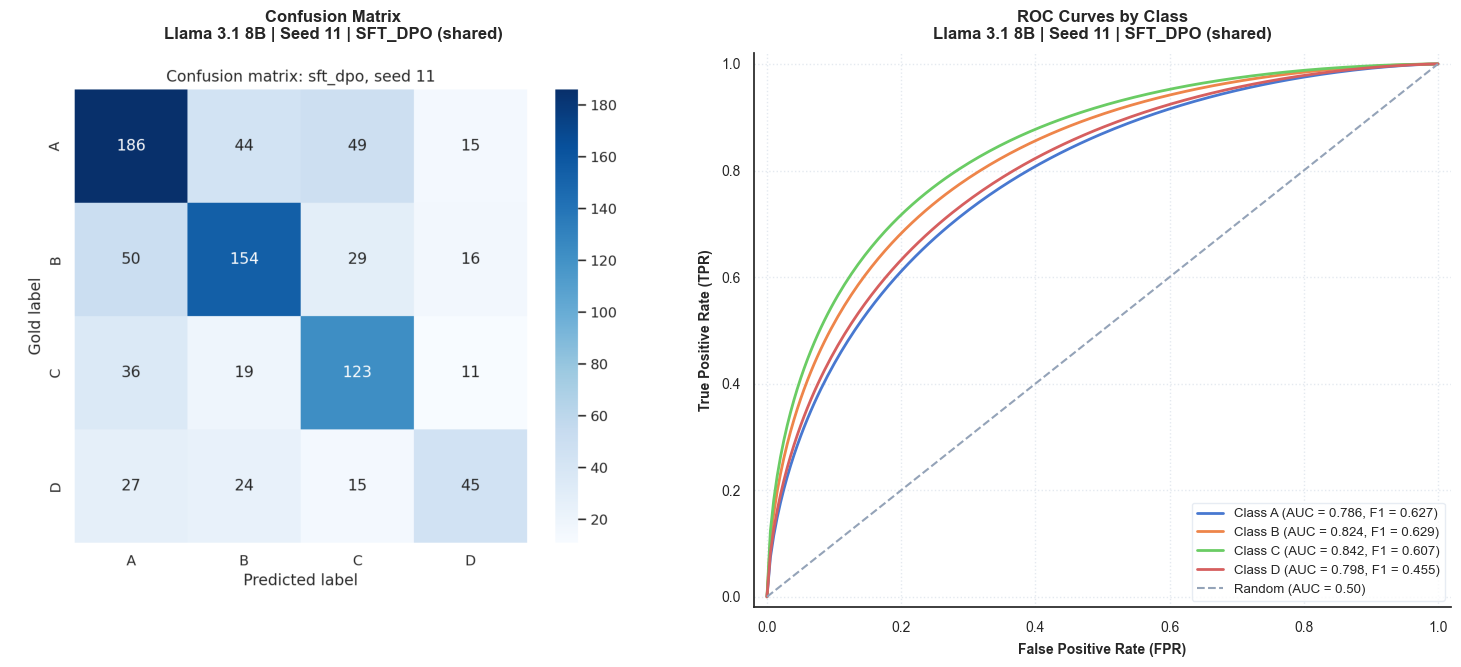

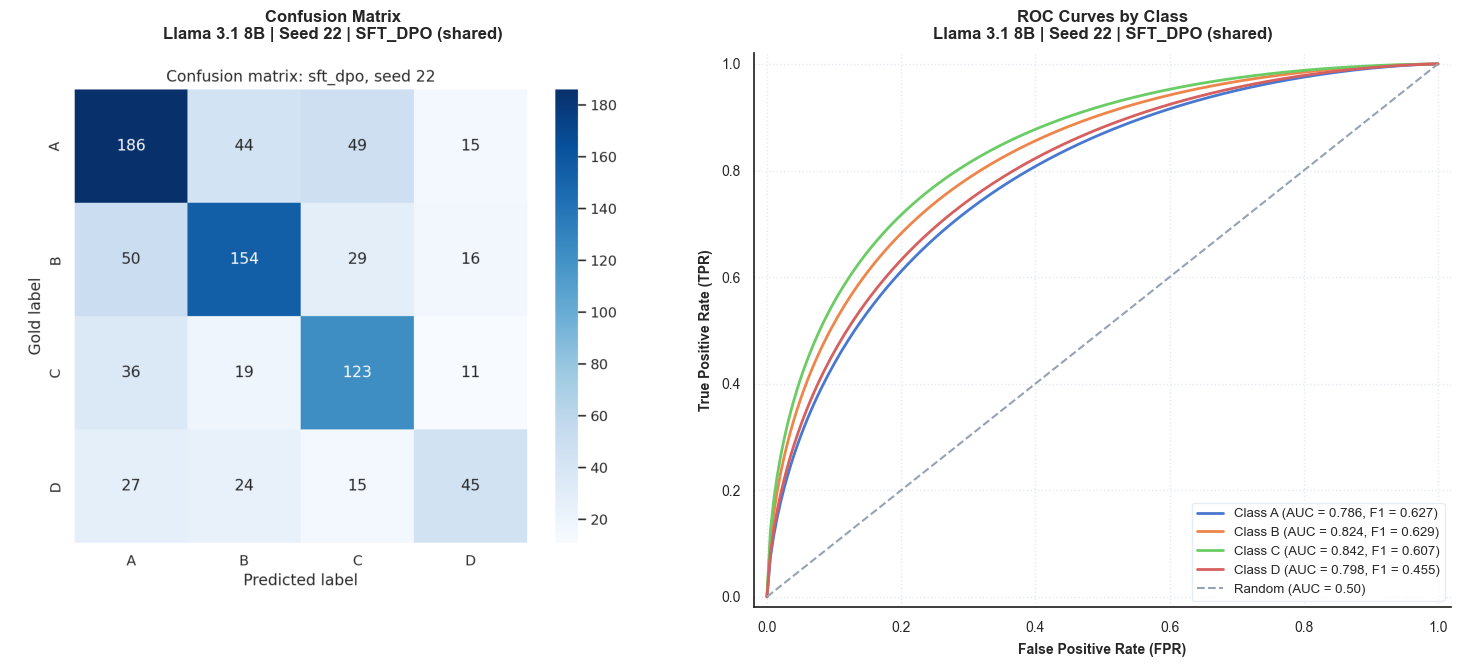

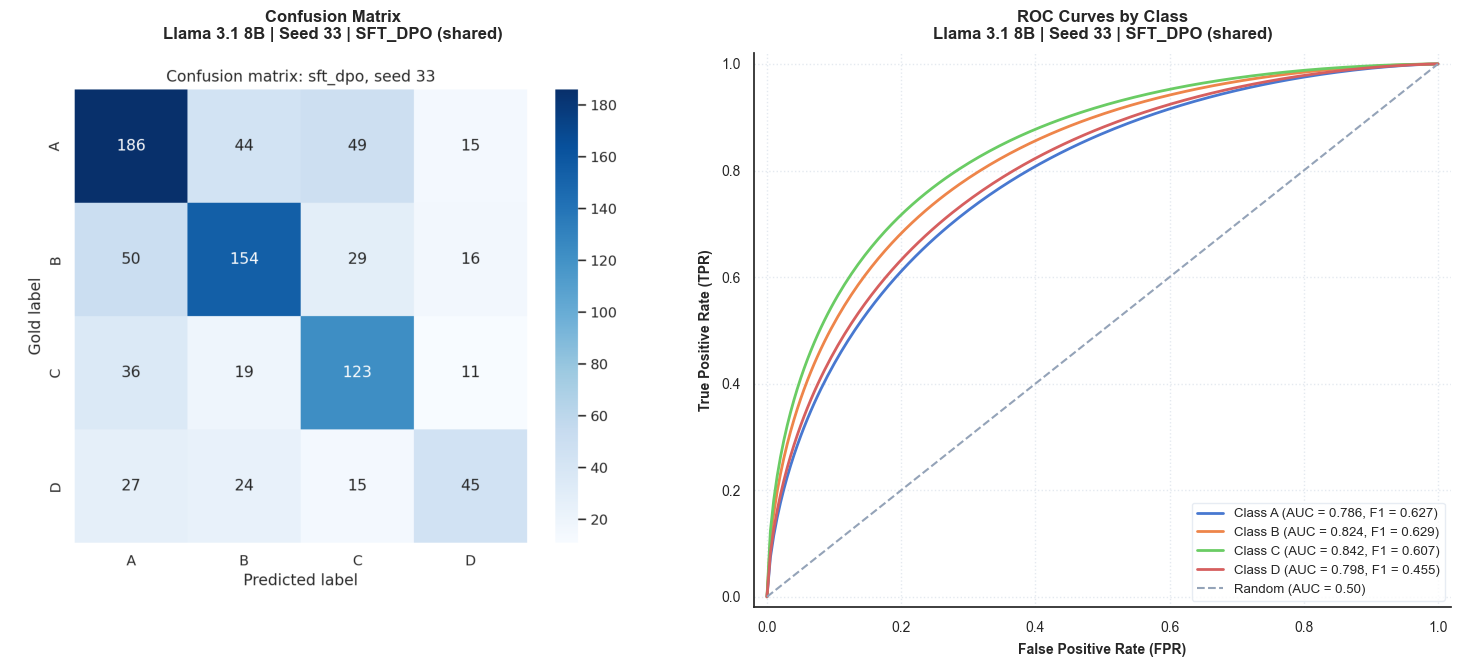

In [14]:
for seed in [11, 22, 33]:
    plot_confusion_and_roc(os.getcwd(), 'Task 1 (Tweets 2020-2021)', 'ds1_task6', 'Llama 3.1 8B', 'llama31', 'sft_dpo', 'shared', seed)

### Task 2: News Articles (2020-2021) - Problem/Solution (Llama 3.1 8B SFT+DPO Shared)

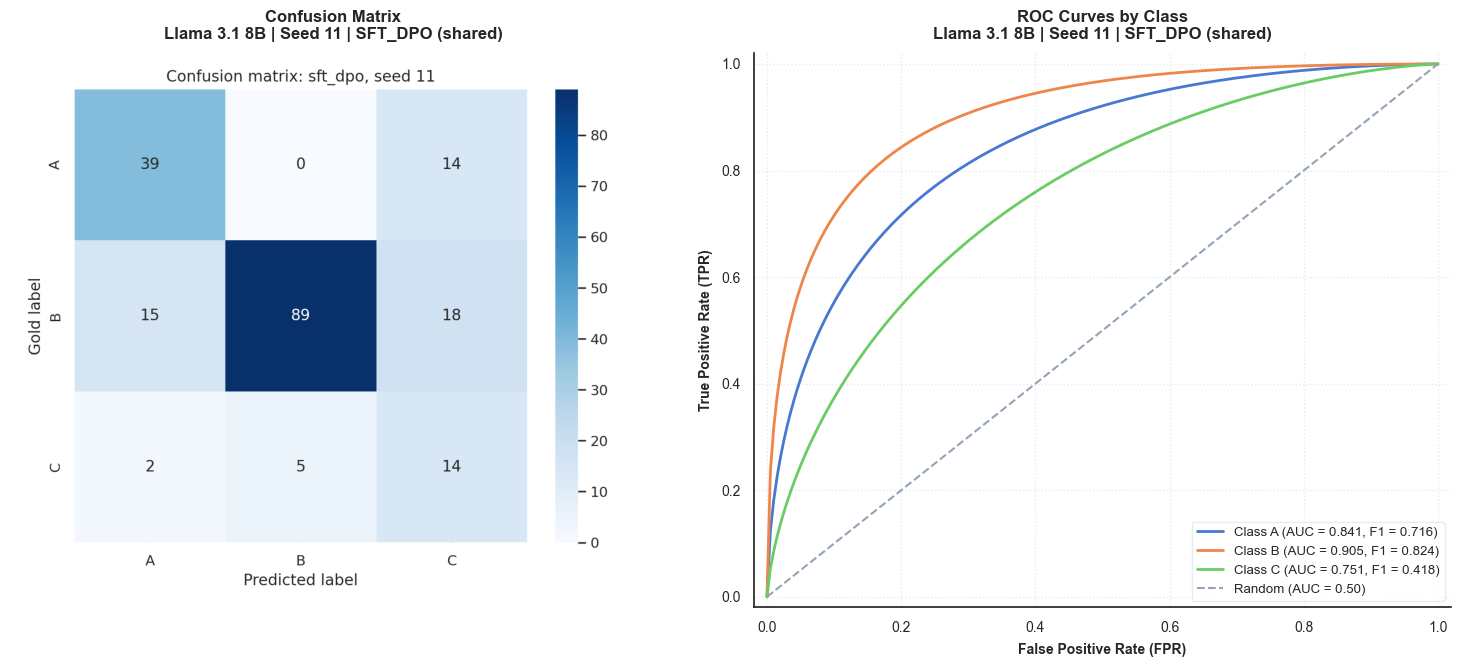

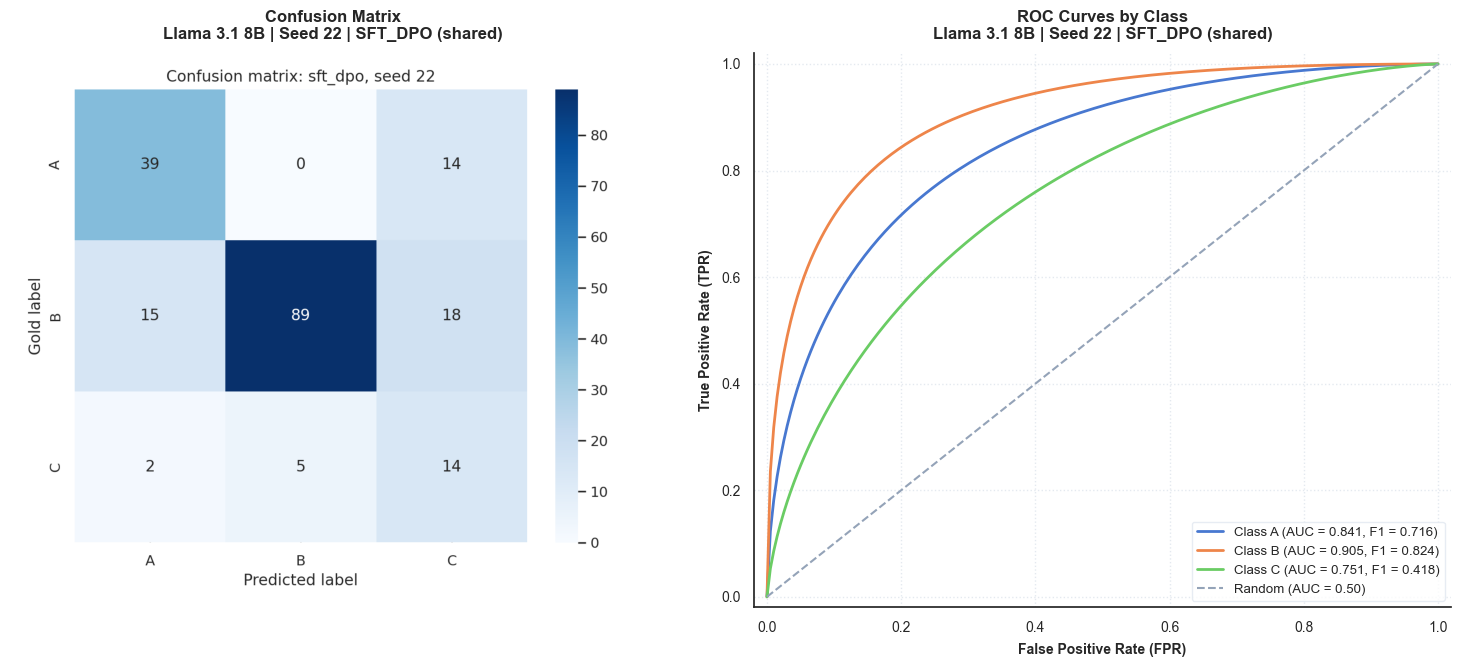

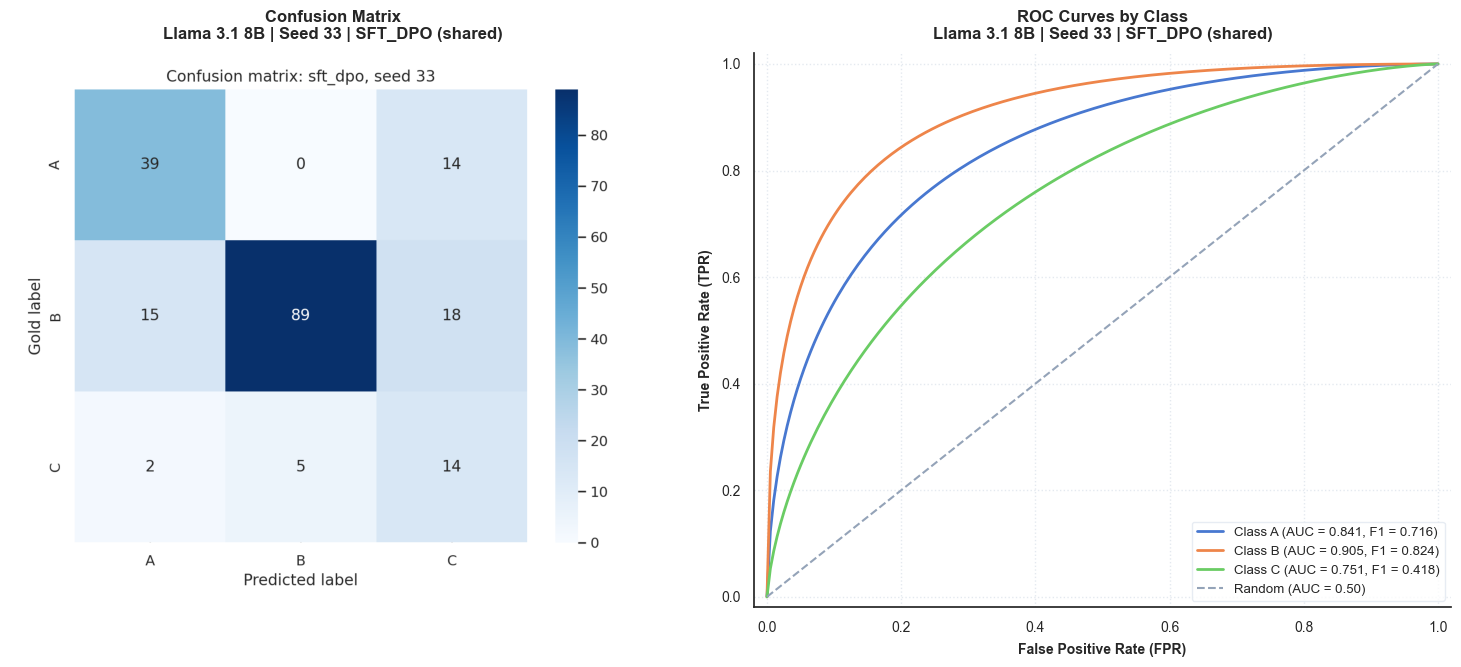

In [15]:
for seed in [11, 22, 33]:
    plot_confusion_and_roc(os.getcwd(), 'Task 2 (News Articles 2020-2021)', 'ds4_task2', 'Llama 3.1 8B', 'llama31', 'sft_dpo', 'shared', seed)

### Task 3: Tweets (2017-2022) - Policy Frames (Llama 3.1 8B SFT+DPO Shared)

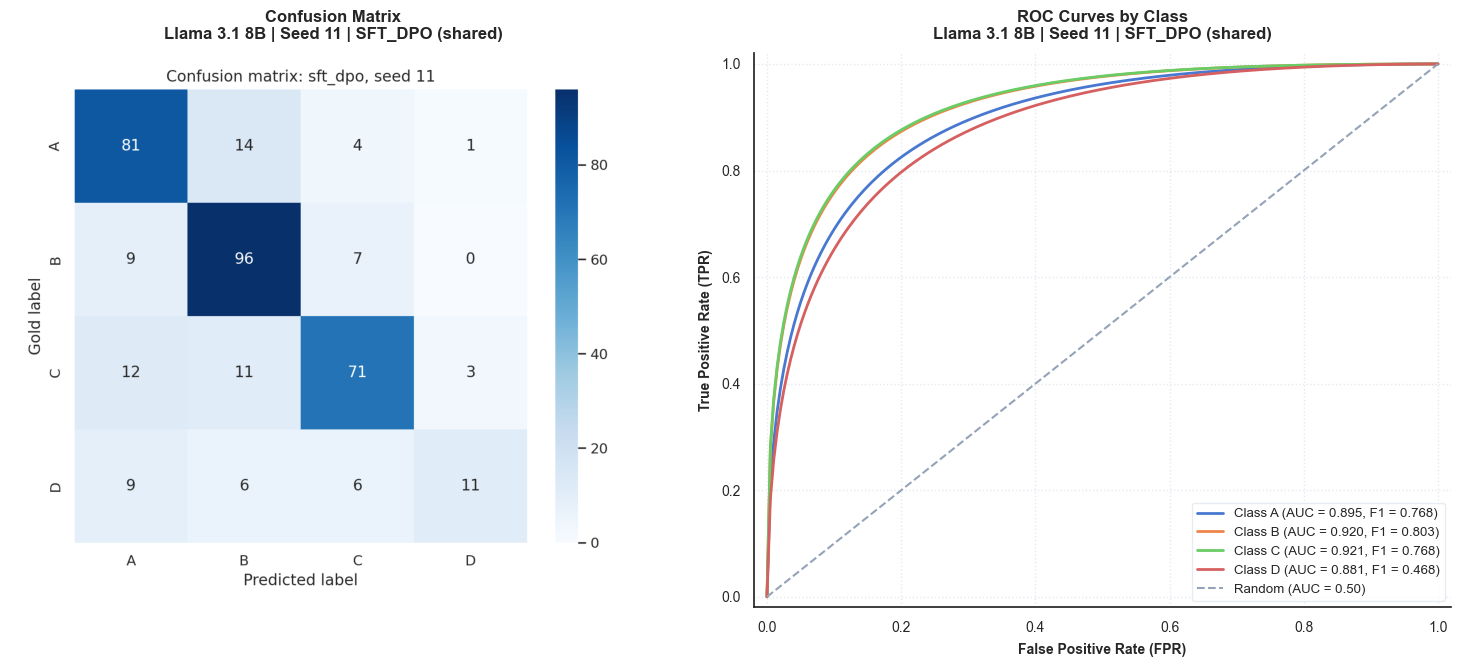

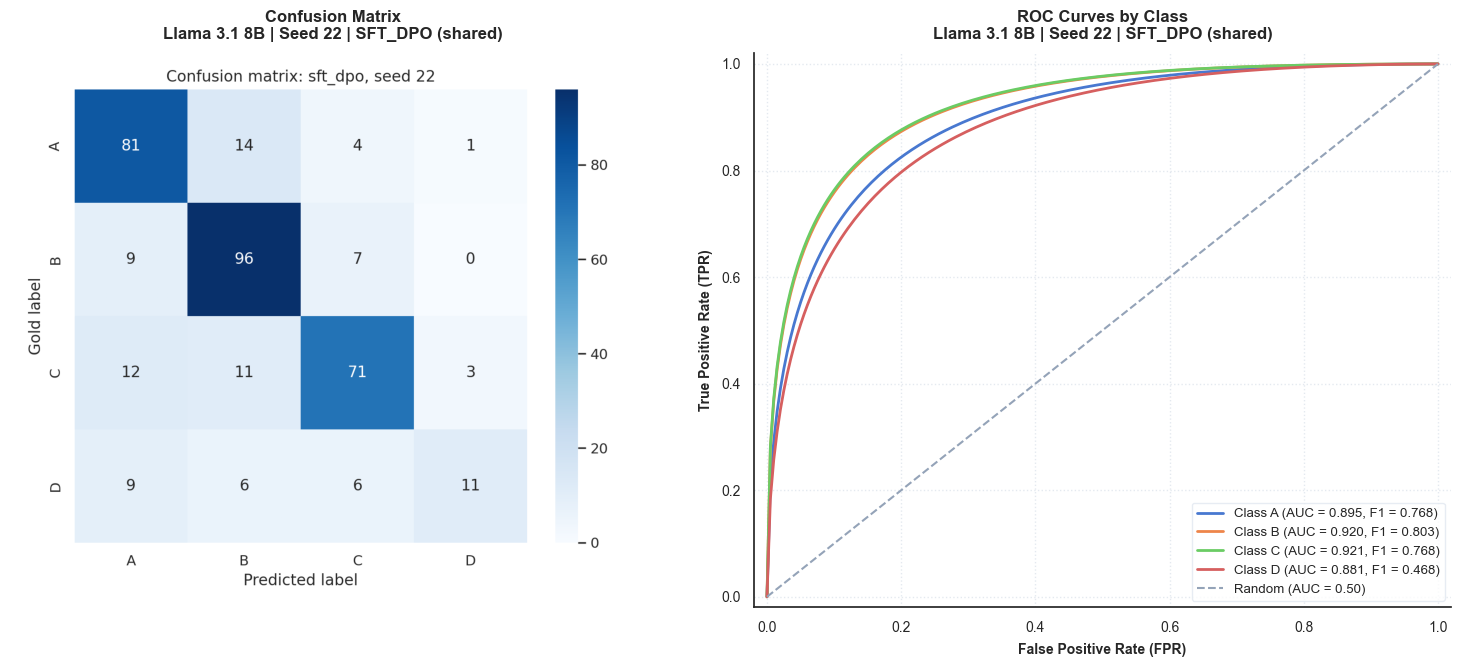

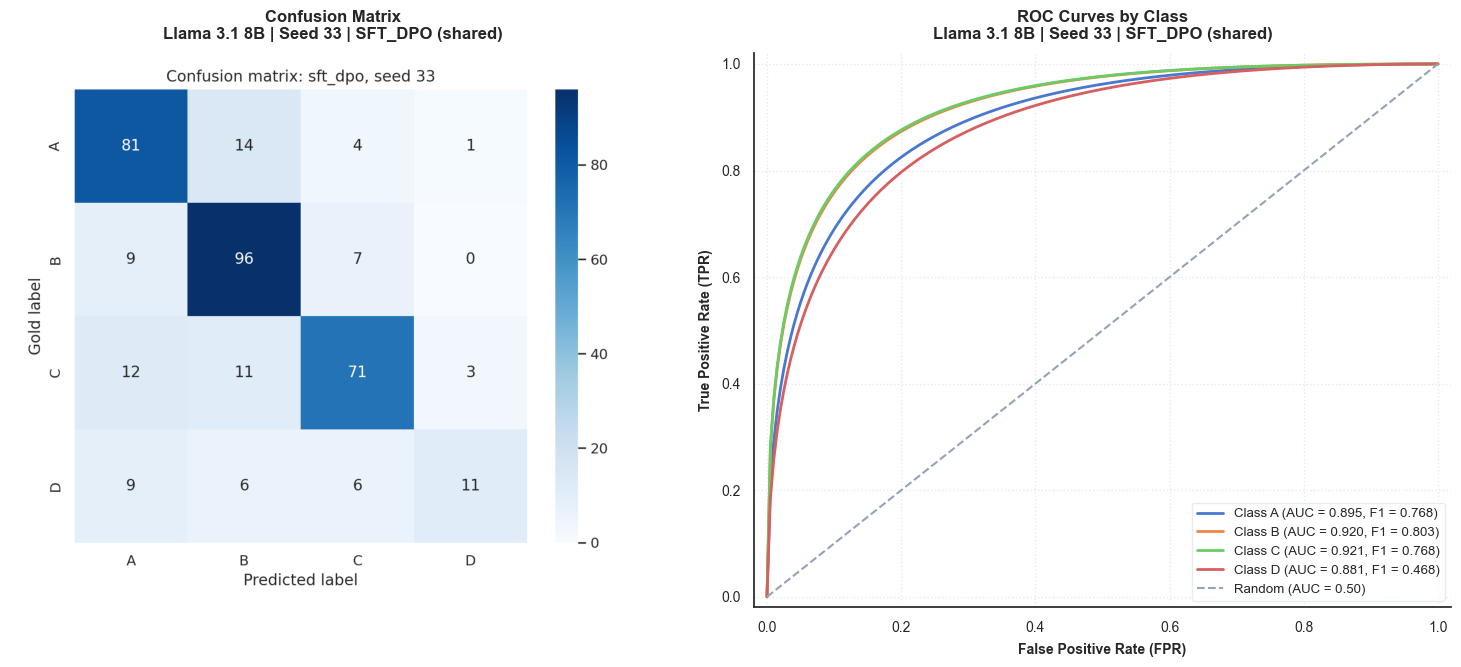

In [16]:
for seed in [11, 22, 33]:
    plot_confusion_and_roc(os.getcwd(), 'Task 3 (Tweets 2017-2022)', 'ds3_task6', 'Llama 3.1 8B', 'llama31', 'sft_dpo', 'shared', seed)